# **Item-item Collaborative Filtering**

---

RecSys Exercise 4, April 20, 2021

## **Overview**
In this exercise you  will explore item-based collaborative filtering.


***Please upload in Moodle this notebook (executable and in PDF) with the code and answers to the posted questions. ***

## **Instructions**

Before you start just to remind the intuitive algorithm of the item-item collaborative filtering:



1.   Compute similarity between pairs of items (cosine similarity).

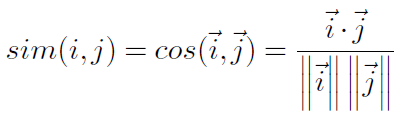
2.   Isolate the set of the most similar items based on the similarity measures.
(correlation values: 1, the most similar user to −1, the least similar user).
3. Compute the prediction score on an item *i* (that a user u has not rated) by adding the
ratings *r(i, j)* given by the user *u* on items similar to *i*. Each rating is weighted by the corresponding similarity *s(i, j)* between items *i* and *j*.

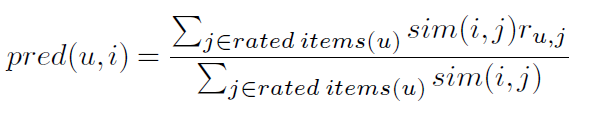
4. Recommend to the user the items with the highest prediction scores.



# **Task 1: Compute item-item similarity**

For this task please use the dataset named `movie_ratings.csv`. You can compare the dataset to a 20x20 matrix where columns represent
users, rows represent movies, and each cell represents a user-movie rating (a value of 0 means that
the user has not rated that movie). Note that the library `sklearn` is being used to compute the
cosine similarity between the items.

The code provided performs the computation of the cosine similarity between items. Note that
the function `cosine_similarity` returns a Numpy data type and therefore the output has been
converted to a `Pandas` data frame named `item_item_corr_matrix`. This variable contains the
similarity values between items.


In [1]:
#Exercise 4: Item-Item Filtering
#Authors: Mirzargar

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

import math

#**********************MAIN PROGRAM*******************************************************************
# read data
#
movie_ratings = pd.read_csv('movies_rating.csv', header=0, index_col='Movie')

print(movie_ratings)

#Calculating the cosine similarity across items. Note that the cosine_similarity function depends from the sklearn library
#As the cosine_similarity function returns an array, we create a new data frame and assign the names to columns and rows
#which come from the original dataframe

name_movies= list(movie_ratings.index)

item_item_corr_matrix= pd.DataFrame(cosine_similarity(movie_ratings), columns=name_movies, index=name_movies)
print("\nSimilarity Matrx: \n")
print(item_item_corr_matrix)



                                                   Pedro  Pablo  ...  Betty  Denisse
Movie                                                            ...                
Toy Story (1995)                                       2      1  ...      2        2
Star Wars: Episode VI - Return of the Jedi (1983)      5      0  ...      1        2
 Forrest Gump (1994)                                   2      0  ...      3        2
Shawshank Redemption, The (1994)                       0      2  ...      0        4
Silence of the Lambs, The (1991)                       4      4  ...      0        5
Gladiator (2000)                                       4      2  ...      4        0
Star Wars: Episode IV - A New Hope (1977)              1      5  ...      5        1
Saving Private Ryan (1998)                             2      0  ...      1        3
Pulp Fiction (1994)                                    0      0  ...      3        2
Stand by Me (1986)                                     3      4  

**Provide the title of the five (5) most similar movies to Toy Story, in decreasing order of similarity.**

In [2]:
#Write your code here
#the dataframe has been sliced from the index 1, since in the index 0 the value will be 1.00 (self-correlation)
corr_top5 = (item_item_corr_matrix.loc['Toy Story (1995)'].sort_values(ascending=False)[1:6]).to_frame().T
corr_top5

,Star Wars: Episode IV - A New Hope (1977),Independence Day (ID4) (1996),Pulp Fiction (1994),"Shawshank Redemption, The (1994)",Groundhog Day (1993)
Toy Story (1995),0.747409,0.690665,0.667846,0.667424,0.661016


> *Answer:*
>* Star Wars: Episode IV - A New Hope (1977), *similarity: 07474*
>* Independence Day (ID4) (1996), *similarity: 06906*
>* Pulp Fiction (1994), *similarity: 06678*
>* Shawshank Redemption, The (1994), *similarity: 0674*
>* Groundhog Day (1993), *similarity: 06610*


# **Task 2: Compute a prediction score for target itms**

Provide a prediction score for *all* the movies that user *Pablo* has not rated yet. To perform this task take into consideration the following:



*   The rating for a movie that the user has not rated is equal to zero (0).
*   You already have a similarity matrix with similarity values among the movies.
*  Refer to the step 3 of the Instructions section. There you will find the formula that you need to use to obtain the prediction scores on unrated items. For the sake of this exercise, you will not select the most similar items, you will have to use all the similarity values of all the rated items by the user.


**Hint:** The prediction score for the movie Star Wars: Episode VI - Return of the Jedi (1983) is of 2.774


In [3]:
#Write your code here

# ratings_corr_list contains tuples of: rating of user u for movie (j), similarity of movies (i,j) 
def sumproduct(ratings_corr_list):
    sum = 0
    for i in range(len(ratings_corr_list)):
            sum = sum + (ratings_corr_list[i][0] * ratings_corr_list[i][1])
    return sum

def sumif(ratings_corr_list):
    
    sum = 0
    for i in range(len(ratings_corr_list)):
            sum = sum + ratings_corr_list[i][1]
    return sum

def prediction(ratings_corr_list):

    return sumproduct(ratings_corr_list) / sumif(ratings_corr_list)
     

In [22]:
ratings = movie_ratings['Pablo']
movies = movie_ratings.index.values.tolist()

In [15]:
#contains the tuple of (idx, rating), for all the movies the user has watched
rated_movies = []
not_rated_movies = []

ratings_list = list(ratings)

for idx in range(len(ratings_list)):
  if (ratings_list[idx] != 0):
    rated_movies.append((idx, ratings_list[idx]))
  else:
    not_rated_movies.append(idx)

In [11]:
#contains our prediction for all the movies, 
#if the user has already rated the movie, our prediction is equal to the user's rating
#else, we will use the given formula to calculate it
prediction_list = []

#iterate over all the ratings

for idx in range(len(ratings_list)):

  #if the user has not rated this movie

  if (ratings_list[idx] == 0):

    #calculate the prediction
  
    #Store all the similarities for the current movie (idx)
    sim_list = item_item_corr_matrix.loc[movies[idx]].tolist()
  
    #find the ratings of this user for these similar movies
    user_rating_sim_list = []
    #iterate over all the movies that the user has already rated
    for idx_2, r in rated_movies:
        
        user_rating_sim_list.append((r,sim_list[idx_2]))
  
    prediction_list.append(prediction(user_rating_sim_list))
  
  #if user has already rated this movie

  else:
  
    #prediction is the rating of the user
    prediction_list.append(ratings_list[idx])

In [12]:
movie_ratings['Prediction']=prediction_list
movie_ratings

,Pedro,Pablo,Arianna,Marcos,Arielle,Gio,Sofia,Moreno,Prisca,Tue,Paula,Letty,James,Osito,Eva,Vanessa,Ginger,Allan,Betty,Denisse,Prediction
Movie,,,,,,,,,,,,,,,,,,,,,
Toy Story (1995),2,1,0,2,0,3,0,2,4,4,5,2,4,3,2,0,2,4,2,2,1.000000
Star Wars: Episode VI - Return of the Jedi (1983),5,0,0,3,3,4,0,0,1,2,1,5,0,0,4,0,0,5,1,2,2.774215
Forrest Gump (1994),2,0,0,0,4,4,3,0,0,0,5,2,0,3,0,1,0,1,3,2,2.708550
"Shawshank Redemption, The (1994)",0,2,5,0,1,4,1,0,4,5,0,0,5,0,0,0,0,5,0,4,2.000000
"Silence of the Lambs, The (1991)",4,4,2,0,4,0,1,3,2,3,0,0,4,2,5,3,0,1,0,5,4.000000
Gladiator (2000),4,2,0,1,1,0,4,2,4,0,5,0,0,0,5,2,0,1,4,0,2.000000
Star Wars: Episode IV - A New Hope (1977),1,5,0,0,4,2,4,4,5,4,2,3,2,3,4,0,0,4,5,1,5.000000
Saving Private Ryan (1998),2,0,0,3,4,1,5,0,4,3,0,0,5,0,0,2,0,0,1,3,2.780218
Pulp Fiction (1994),0,0,0,4,0,4,2,3,0,4,0,1,0,0,3,0,2,5,3,2,2.802797


In [31]:
for idx in not_rated_movies:
  print(movies[idx])
  print("prediction: " + str(movie_ratings.loc[movies[idx],'Prediction']))

Star Wars: Episode VI - Return of the Jedi (1983)
prediction: 2.774215215830408
 Forrest Gump (1994)
prediction: 2.708550273096228
Saving Private Ryan (1998)
prediction: 2.780218122072276
Pulp Fiction (1994)
prediction: 2.8027971011907162
Blade Runner (1982)
prediction: 2.7842520940793496
Matrix, The (1999)
prediction: 2.770176203123428
Babe (1995)
prediction: 2.610945418586956


> *Answer:*


1.   Star Wars: Episode VI - Return of the Jedi (1983) *prediction: 2.774215215830408*
2.   Forrest Gump (1994) *prediction: 2.708550273096228*
3.   Saving Private Ryan (1998) *prediction: 2.780218122072276*
4.   Pulp Fiction (1994) *prediction: 2.8027971011907162*
5.   Blade Runner (1982) *prediction: 2.7842520940793496*
6.   Matrix, The (1999)  *prediction: 2.770176203123428*
7.   Babe (1995)         *prediction: 2.610945418586956*



 


# **Task 3: Answer the following**



* Using the prediction scores computed in *Task *2, which movie will you recommend to the user Pablo?
> *Answer:* Pulp Fiction because it has the highest prediction score

* What are the main differences between User-User and Item-Item collaborative filtering?
> *Answer:* While in U2U filtering, one find the users that are similar to the active user, in I2I filtering, we look for items that are similar to the items that the active user has purchased.

 > If number of users in the system is high, then the user-item matrix will be *sparse* and computing pairwise user-user corrolations can be very expensive (even if using incremental methods). *Items usually have more ratings compare to an average user*. Also, users might change their taste through time, therfore, one needs to update user-user neighborhouds.*Item-item similarities are almost stable* because item characterisitcs are almost constant (at least in rating spase) and one can *pre-compute* item-item similarities. 

 >One disadvantage of I2I filtering is that it has *low serendipity* compared to U2U (recommending some unplanned fortunate discoveries)

* Under which circumstances will you prefer Item-Item collaborative filtering over User-User collaborative filtering?
> *Answer:*
When:
>1.  number of users are much larger than the number of items
>2.  low serendipity is not an issue for the recommendations
>3.  users tend to change their taste and preferences
>4.  Bounded by amount of computations or rate of updates for the neighborhouds
